In [ ]:
# AVPF1 - CONCRETO PERMEABLE
# Resistencia a la compresión y permeabilidad

print("AVPF1 - CONCRETO PERMEABLE")
print("Análisis de resistencia a la compresión y permeabilidad")
print("Ingeniería Civil - Estructuras y Materiales")

AVPF1 - CONCRETO PERMEABLE
Análisis de resistencia a la compresión y permeabilidad
Ingeniería Civil - Estructuras y Materiales


In [ ]:
# Importamos las librerías necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración para visualizar mejor los datos
pd.set_option('display.max_columns', None)

# Mostrar los valores numéricos con 3 decimales
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
# CREACIÓN DE LA BASE DE DATOS

# Datos organizados según:
# - Tipo de agregado
# - Gradación
# - Porosidad
# - Relación agua/cemento
# - Resistencia a la compresión
# - Permeabilidad

datos = {
    ("Granite", "5-10 mm"): {
        12: ([17.2, 53.4, 48.3], [1.38, 0.30, 0.17]),
        15: ([13.0, 32.6, 35.9], [1.48, 0.55, 0.40]),
        18: ([9.9, 30.3, 28.5], [1.73, 1.25, 0.63]),
        21: ([7.6, 22.3, 23.8], [1.95, 2.29, 1.45])
    },

    ("Granite", "50% 5-10 + 50% 10-15 mm"): {
        12: ([13.9, 56.9, 47.3], [0.65, 0.28, 0.24]),
        15: ([25.8, 38.5, 37.8], [1.27, 2.37, 2.29]),
        18: ([10.4, 32.5, 34.9], [1.68, 1.05, 1.09]),
        21: ([13.9, 23.6, 26.6], [2.87, 2.37, 2.29])
    },

    ("Granite", "10-15 mm"): {
        12: ([9.6, 53.6, 44.6], [0.63, 0.28, 0.12]),
        15: ([17.8, 35.0, 32.6], [1.21, 0.45, 0.40]),
        18: ([14.7, 31.5, 29.2], [2.98, 1.09, 0.79]),
        21: ([9.6, 23.6, 21.4], [4.50, 2.13, 0.94])
    },

    ("Dolerite", "5-10 mm"): {
        12: ([23.5, 53.7, 49.9], [1.42, 0.42, 0.19]),
        15: ([21.2, 37.8, 36.3], [1.63, 1.05, 0.82]),
        18: ([27.1, 32.8, 30.9], [2.77, 1.73, 1.02]),
        21: ([11.8, 25.6, 24.6], [2.23, 3.44, 2.21])
    }
}

# Lista donde almacenaremos cada registro
filas = []

# Recorrer los datos para construir el DataFrame
for (agregado, gradacion), valores in datos.items():

    for porosidad, (resistencias, permeabilidades) in valores.items():

        # Cada combinación tiene tres relaciones agua/cemento
        relaciones_ac = [0.20, 0.25, 0.30]

        for ac, resistencia, permeabilidad in zip(
            relaciones_ac,
            resistencias,
            permeabilidades
        ):

            filas.append({
                "Agregado": agregado,
                "Gradacion": gradacion,
                "Porosidad_pct": porosidad,
                "Relacion_agua_cemento": ac,
                "Resistencia_compresion_MPa": resistencia,
                "Permeabilidad_mm_s": permeabilidad
            })

# Convertimos la lista en DataFrame
df = pd.DataFrame(filas)

print("Base de datos creada correctamente.")
print("Número de registros:", len(df))

# Mostrar los primeros registros
df.head()

Base de datos creada correctamente.
Número de registros: 48


,Agregado,Gradacion,Porosidad_pct,Relacion_agua_cemento,Resistencia_compresion_MPa,Permeabilidad_mm_s
0,Granite,5-10 mm,12,0.200,17.200,1.380
1,Granite,5-10 mm,12,0.250,53.400,0.300
2,Granite,5-10 mm,12,0.300,48.300,0.170
3,Granite,5-10 mm,15,0.200,13.000,1.480
4,Granite,5-10 mm,15,0.250,32.600,0.550


In [ ]:
# EXPLORACIÓN DE LA BASE DE DATOS

print("Dimensiones de la base de datos:")
print(df.shape)

print("\nInformación general:")
df.info()

Dimensiones de la base de datos:
(48, 6)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Agregado                    48 non-null     object 
 1   Gradacion                   48 non-null     object 
 2   Porosidad_pct               48 non-null     int64  
 3   Relacion_agua_cemento       48 non-null     float64
 4   Resistencia_compresion_MPa  48 non-null     float64
 5   Permeabilidad_mm_s          48 non-null     float64
dtypes: float64(3), int64(1), object(2)
memory usage: 2.4+ KB


In [ ]:
# Mostrar los primeros 10 registros

df.head(10)

,Agregado,Gradacion,Porosidad_pct,Relacion_agua_cemento,Resistencia_compresion_MPa,Permeabilidad_mm_s
0,Granite,5-10 mm,12,0.200,17.200,1.380
1,Granite,5-10 mm,12,0.250,53.400,0.300
2,Granite,5-10 mm,12,0.300,48.300,0.170
3,Granite,5-10 mm,15,0.200,13.000,1.480
4,Granite,5-10 mm,15,0.250,32.600,0.550
5,Granite,5-10 mm,15,0.300,35.900,0.400
6,Granite,5-10 mm,18,0.200,9.900,1.730
7,Granite,5-10 mm,18,0.250,30.300,1.250
8,Granite,5-10 mm,18,0.300,28.500,0.630
9,Granite,5-10 mm,21,0.200,7.600,1.950


In [ ]:
# ============================================================
# IDENTIFICACIÓN DE VALORES NULOS
# ============================================================

print("Valores nulos por columna:")
print(df.isnull().sum())

Valores nulos por columna:
Agregado                      0
Gradacion                     0
Porosidad_pct                 0
Relacion_agua_cemento         0
Resistencia_compresion_MPa    0
Permeabilidad_mm_s            0
dtype: int64


In [ ]:
# IDENTIFICACIÓN DE DUPLICADOS

duplicados = df.duplicated().sum()

print("Número de registros duplicados:", duplicados)

Número de registros duplicados: 0


In [ ]:
# LIMPIEZA Y ORGANIZACIÓN DE LOS DATOS

# Convertimos las variables numéricas al formato correspondiente

columnas_numericas = [
    "Porosidad_pct",
    "Relacion_agua_cemento",
    "Resistencia_compresion_MPa",
    "Permeabilidad_mm_s"
]

for columna in columnas_numericas:
    df[columna] = pd.to_numeric(
        df[columna],
        errors="coerce"
    )

# Eliminamos registros con datos faltantes
df = df.dropna(
    subset=columnas_numericas
)

# Eliminamos registros duplicados
df = df.drop_duplicates()

# Reiniciamos el índice
df = df.reset_index(drop=True)

print("Limpieza terminada.")
print("Número de registros después de la limpieza:", len(df))

df.head()

Limpieza terminada.
Número de registros después de la limpieza: 48


,Agregado,Gradacion,Porosidad_pct,Relacion_agua_cemento,Resistencia_compresion_MPa,Permeabilidad_mm_s
0,Granite,5-10 mm,12,0.200,17.200,1.380
1,Granite,5-10 mm,12,0.250,53.400,0.300
2,Granite,5-10 mm,12,0.300,48.300,0.170
3,Granite,5-10 mm,15,0.200,13.000,1.480
4,Granite,5-10 mm,15,0.250,32.600,0.550


In [ ]:
# ESTADÍSTICA DESCRIPTIVA

estadistica = df[columnas_numericas].describe()

estadistica

,Porosidad_pct,Relacion_agua_cemento,Resistencia_compresion_MPa,Permeabilidad_mm_s
count,48.000,48.000,48.000,48.000
mean,16.500,0.250,28.819,1.385
std,3.390,0.041,13.196,0.975
min,12.000,0.200,7.600,0.120
25%,14.250,0.200,20.350,0.610
50%,16.500,0.250,27.800,1.230
75%,18.750,0.300,36.000,2.150
max,21.000,0.300,56.900,4.500


In [ ]:
# COEFICIENTE DE VARIACIÓN

resumen = df[columnas_numericas].describe().T

# Cálculo del coeficiente de variación
resumen["CV_pct"] = (
    resumen["std"] /
    resumen["mean"]
) * 100

# Redondeamos los resultados
resumen = resumen.round(3)

resumen

,count,mean,std,min,25%,50%,75%,max,CV_pct
Porosidad_pct,48.000,16.500,3.390,12.000,14.250,16.500,18.750,21.000,20.543
Relacion_agua_cemento,48.000,0.250,0.041,0.200,0.200,0.250,0.300,0.300,16.503
Resistencia_compresion_MPa,48.000,28.819,13.196,7.600,20.350,27.800,36.000,56.900,45.790
Permeabilidad_mm_s,48.000,1.385,0.975,0.120,0.610,1.230,2.150,4.500,70.400


In [ ]:
# RESULTADOS PRINCIPALES

promedio_resistencia = df[
    "Resistencia_compresion_MPa"
].mean()

promedio_permeabilidad = df[
    "Permeabilidad_mm_s"
].mean()

promedio_porosidad = df[
    "Porosidad_pct"
].mean()

promedio_ac = df[
    "Relacion_agua_cemento"
].mean()

print("PROMEDIOS DEL CONJUNTO DE DATOS")
print("--------------------------------")
print(f"Resistencia promedio: {promedio_resistencia:.2f} MPa")
print(f"Permeabilidad promedio: {promedio_permeabilidad:.2f} mm/s")
print(f"Porosidad promedio: {promedio_porosidad:.2f} %")
print(f"Relación agua/cemento promedio: {promedio_ac:.2f}")

PROMEDIOS DEL CONJUNTO DE DATOS
--------------------------------
Resistencia promedio: 28.82 MPa
Permeabilidad promedio: 1.39 mm/s
Porosidad promedio: 16.50 %
Relación agua/cemento promedio: 0.25


In [ ]:
# MATRIZ DE CORRELACIÓN

correlacion = df[columnas_numericas].corr()

print("MATRIZ DE CORRELACIÓN")
print("---------------------")

correlacion.round(3)

MATRIZ DE CORRELACIÓN
---------------------


,Porosidad_pct,Relacion_agua_cemento,Resistencia_compresion_MPa,Permeabilidad_mm_s
Porosidad_pct,1.000,0.000,-0.545,0.692
Relacion_agua_cemento,0.000,1.000,0.597,-0.405
Resistencia_compresion_MPa,-0.545,0.597,1.000,-0.590
Permeabilidad_mm_s,0.692,-0.405,-0.590,1.000


In [ ]:
# CORRELACIÓN ENTRE RESISTENCIA Y PERMEABILIDAD

r_resistencia_permeabilidad = np.corrcoef(
    df["Resistencia_compresion_MPa"],
    df["Permeabilidad_mm_s"]
)[0, 1]

print(
    f"Coeficiente de correlación: "
    f"{r_resistencia_permeabilidad:.3f}"
)

if r_resistencia_permeabilidad < 0:
    print(
        "Interpretación: existe una relación negativa. "
        "En general, cuando aumenta la permeabilidad, "
        "la resistencia tiende a disminuir."
    )
else:
    print(
        "Interpretación: existe una relación positiva."
    )

Coeficiente de correlación: -0.590
Interpretación: existe una relación negativa. En general, cuando aumenta la permeabilidad, la resistencia tiende a disminuir.


In [ ]:
# REGRESIÓN LINEAL

x = df["Permeabilidad_mm_s"].to_numpy()
y = df["Resistencia_compresion_MPa"].to_numpy()

# Calculamos pendiente e intercepto
pendiente, intercepto = np.polyfit(x, y, 1)

# Predicciones
y_pred = intercepto + pendiente * x

# Coeficiente R
r = np.corrcoef(x, y)[0, 1]

# Coeficiente de determinación
r2 = r ** 2

print("REGRESIÓN LINEAL")
print("----------------")
print(f"Pendiente: {pendiente:.3f}")
print(f"Intercepto: {intercepto:.3f}")
print(f"Coeficiente r: {r:.3f}")
print(f"Coeficiente R²: {r2:.3f}")

print(
    f"\nEcuación:\n"
    f"Resistencia = {intercepto:.3f} "
    f"+ ({pendiente:.3f}) × Permeabilidad"
)

REGRESIÓN LINEAL
----------------
Pendiente: -7.984
Intercepto: 39.876
Coeficiente r: -0.590
Coeficiente R²: 0.348

Ecuación:
Resistencia = 39.876 + (-7.984) × Permeabilidad


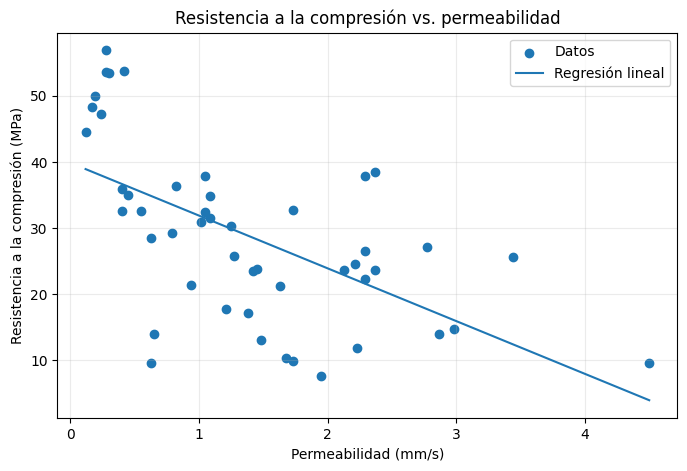

In [ ]:
# GRÁFICO 1
# RESISTENCIA A LA COMPRESIÓN VS PERMEABILIDAD

plt.figure(figsize=(8,5))

plt.scatter(
    df["Permeabilidad_mm_s"],
    df["Resistencia_compresion_MPa"],
    label="Datos"
)

# Línea de tendencia
x_linea = np.linspace(
    df["Permeabilidad_mm_s"].min(),
    df["Permeabilidad_mm_s"].max(),
    100
)

y_linea = (
    intercepto +
    pendiente * x_linea
)

plt.plot(
    x_linea,
    y_linea,
    label="Regresión lineal"
)

plt.title(
    "Resistencia a la compresión vs. permeabilidad"
)

plt.xlabel(
    "Permeabilidad (mm/s)"
)

plt.ylabel(
    "Resistencia a la compresión (MPa)"
)

plt.grid(alpha=0.25)
plt.legend()

plt.show()

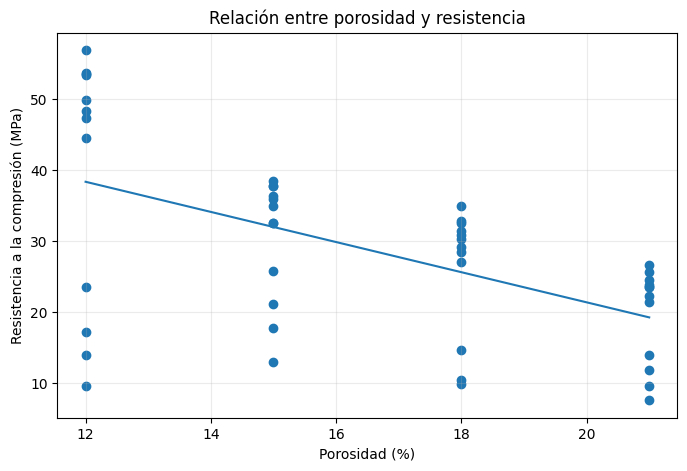

In [ ]:
# GRÁFICO 2
# POROSIDAD VS RESISTENCIA

coeficiente = np.polyfit(
    df["Porosidad_pct"],
    df["Resistencia_compresion_MPa"],
    1
)

x_porosidad = np.linspace(
    df["Porosidad_pct"].min(),
    df["Porosidad_pct"].max(),
    100
)

y_resistencia = (
    coeficiente[0] * x_porosidad +
    coeficiente[1]
)

plt.figure(figsize=(8,5))

plt.scatter(
    df["Porosidad_pct"],
    df["Resistencia_compresion_MPa"]
)

plt.plot(
    x_porosidad,
    y_resistencia
)

plt.title(
    "Relación entre porosidad y resistencia"
)

plt.xlabel(
    "Porosidad (%)"
)

plt.ylabel(
    "Resistencia a la compresión (MPa)"
)

plt.grid(alpha=0.25)

plt.show()

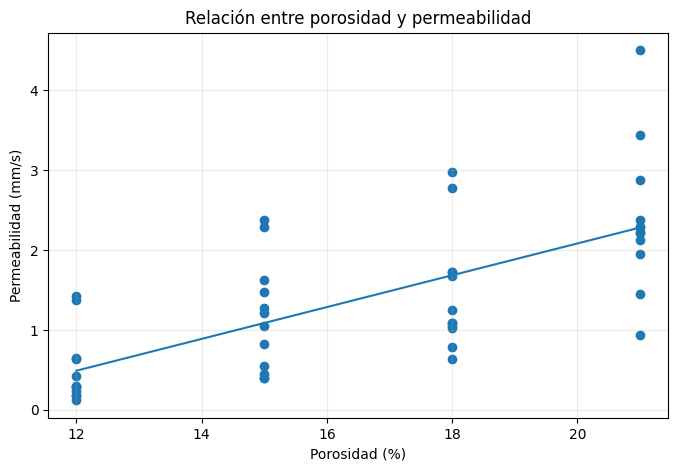

In [ ]:
# GRÁFICO 3
# POROSIDAD VS PERMEABILIDAD

coeficiente_permeabilidad = np.polyfit(
    df["Porosidad_pct"],
    df["Permeabilidad_mm_s"],
    1
)

x_porosidad = np.linspace(
    df["Porosidad_pct"].min(),
    df["Porosidad_pct"].max(),
    100
)

y_permeabilidad = (
    coeficiente_permeabilidad[0] *
    x_porosidad +
    coeficiente_permeabilidad[1]
)

plt.figure(figsize=(8,5))

plt.scatter(
    df["Porosidad_pct"],
    df["Permeabilidad_mm_s"]
)

plt.plot(
    x_porosidad,
    y_permeabilidad
)

plt.title(
    "Relación entre porosidad y permeabilidad"
)

plt.xlabel(
    "Porosidad (%)"
)

plt.ylabel(
    "Permeabilidad (mm/s)"
)

plt.grid(alpha=0.25)

plt.show()

In [ ]:
# COMPARACIÓN SEGÚN TIPO DE AGREGADO

comparacion_agregado = df.groupby(
    "Agregado"
)[
    [
        "Resistencia_compresion_MPa",
        "Permeabilidad_mm_s"
    ]
].mean()

comparacion_agregado.round(3)

,Resistencia_compresion_MPa,Permeabilidad_mm_s
Agregado,,
Dolerite,31.267,1.578
Granite,28.003,1.321


In [ ]:
# COMPARACIÓN SEGÚN RELACIÓN AGUA/CEMENTO

comparacion_ac = df.groupby(
    "Relacion_agua_cemento"
)[
    [
        "Resistencia_compresion_MPa",
        "Permeabilidad_mm_s"
    ]
].mean()

comparacion_ac.round(3)

,Resistencia_compresion_MPa,Permeabilidad_mm_s
Relacion_agua_cemento,,
0.200,15.438,1.899
0.250,36.481,1.316
0.300,34.538,0.941


In [ ]:
# EXPORTACIÓN DE RESULTADOS A EXCEL

nombre_archivo = "Reporte_AVPF1_G1.xlsx"

with pd.ExcelWriter(
    nombre_archivo,
    engine="openpyxl"
) as writer:

    # Hoja 1: datos procesados
    df.to_excel(
        writer,
        sheet_name="Datos_procesados",
        index=False
    )

    # Hoja 2: resumen estadístico
    resumen.reset_index().rename(
        columns={"index": "Variable"}
    ).to_excel(
        writer,
        sheet_name="Resumen_estadistico",
        index=False
    )

    # Hoja 3: matriz de correlaciones
    correlacion.to_excel(
        writer,
        sheet_name="Correlaciones"
    )

    # Hoja 4: resultados principales
    resultados = pd.DataFrame({
        "Indicador": [
            "Número de observaciones",
            "Resistencia promedio (MPa)",
            "Permeabilidad promedio (mm/s)",
            "Porosidad promedio (%)",
            "Relación agua/cemento promedio",
            "Correlación resistencia-permeabilidad",
            "R² resistencia-permeabilidad"
        ],

        "Valor": [
            len(df),
            promedio_resistencia,
            promedio_permeabilidad,
            promedio_porosidad,
            promedio_ac,
            r_resistencia_permeabilidad,
            r2
        ]
    })

    resultados.to_excel(
        writer,
        sheet_name="Resultados_principales",
        index=False
    )

print(
    f"Archivo '{nombre_archivo}' "
    "generado correctamente."
)

Archivo 'Reporte_AVPF1_G1.xlsx' generado correctamente.


In [ ]:
# Descargar el archivo Excel generado

from google.colab import files

files.download(
    "Reporte_AVPF1_G1.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# RESUMEN AUTOMÁTICO DE RESULTADOS

print("==========================================")
print("       RESUMEN DEL ANÁLISIS")
print("==========================================")

print(f"\nNúmero de registros: {len(df)}")

print(
    f"Resistencia promedio: "
    f"{promedio_resistencia:.2f} MPa"
)

print(
    f"Permeabilidad promedio: "
    f"{promedio_permeabilidad:.2f} mm/s"
)

print(
    f"Porosidad promedio: "
    f"{promedio_porosidad:.2f} %"
)

print(
    f"Relación agua/cemento promedio: "
    f"{promedio_ac:.2f}"
)

print(
    f"\nCorrelación resistencia-permeabilidad: "
    f"{r_resistencia_permeabilidad:.3f}"
)

print(
    f"Coeficiente R²: "
    f"{r2:.3f}"
)

print("\nInterpretación:")
print(
    "La relación entre resistencia y permeabilidad "
    "presenta una tendencia negativa. Por lo tanto, "
    "el incremento de la capacidad de infiltración "
    "debe analizarse conjuntamente con la resistencia "
    "requerida para la aplicación de Ingeniería Civil."
)

       RESUMEN DEL ANÁLISIS

Número de registros: 48
Resistencia promedio: 28.82 MPa
Permeabilidad promedio: 1.39 mm/s
Porosidad promedio: 16.50 %
Relación agua/cemento promedio: 0.25

Correlación resistencia-permeabilidad: -0.590
Coeficiente R²: 0.348

Interpretación:
La relación entre resistencia y permeabilidad presenta una tendencia negativa. Por lo tanto, el incremento de la capacidad de infiltración debe analizarse conjuntamente con la resistencia requerida para la aplicación de Ingeniería Civil.
